# Assembling the geometric race model

**Question.** Central models beat peripheral models in every tournament so far, yet human peripheral players score about as fast as human central players. Can a peripheral player, playing as well as the game allows, keep up with a central player?

This notebook builds a model of one race between a peripheral and a central agent from the arena's geometry and the game's rules, one component at a time. Each step adds one limit of the real game, and shows what it does to the score rate. It is written to be read for understanding. The analysis that built the model, with its dead ends, is in `nearer_wall_choice.ipynb`.

**Plan**
1. The arena, the task and the score.
2. Step 1: geometry only, both walls known at onset.
3. Step 2: the central agent senses walls with rays.
4. Step 3: the peripheral agent senses walls with rays.
5. Step 4: choosing a wall from partial knowledge.
6. Step 5: inferring where unseen walls are.
7. Step 6: the Δ rule with inference about both walls, and how Δ was identified.
8. Score rate across the steps and across trial configurations.
9. Known problems and limits.

**Choices and assumptions** (full list, with sources, in `READMEs/analytical_modelling_notes.md`)
- The model looks for how well each strategy *can* be played within the game's limits, not for how the trained agents play (user's choice). Turning and movement rates are kept close to the agents', as human players are likely to be less efficient still (user's choice).
- An agent's behaviour may depend only on what its rays have sensed, its own position and heading, and the arena layout. Never on where an unseen wall is (user's rule).
- Key assumption: the central agent always goes High, as trained central agents do (High on 0.998 of 260929 central won trials). This may not be its best play against a peripheral opponent.
- Peripheral agents start from the logged slice-onset positions and headings of the six 260929 peripheral models (2,376 agent-trials). The central agent starts at the exact centre with a random heading.
- No start-up delay, no timing noise, no use of the opponent's position, and the agents do not block each other.
- Trials follow the repo convention (first logged trial dropped, incomplete final trial dropped). Agent simulations have no spawn trial at the arena centre.

**Modules.** All numbers come from `analysis/analytical_race.py` (tests in `tests/test_analytical_race.py`), using the agents' ray sensor from `analysis/agent_raycast.py`.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import data_strings
import data_extraction.data_saving as data_saving
import analysis.analytical_race as ar
import analysis.agent_raycast as agent_raycast
import analysis.agent_loser_choice as lc
import trajectory_analysis.visibility_occlusion as vo

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

RECOMPUTE = False                   # rebuild the cached tables
BATCH = '260929'
SIM_DATA_FOLDER = os.path.join(data_strings.SIM_DATA_FOLDER, '2609', BATCH)
CUT = 0.5                           # peripheral below this mean onset centrality
D_GRID = np.round(np.arange(0, 3.81, 0.05), 2)     # thresholds swept (s); 3.8 s is the longest gap possible

# colours: walls, agents and rules
C_HIGHW, C_LOWW, C_WALL = '#D62728', '#1F77B4', '#AAAAAA'
C_PERIPH, C_CENTRAL, C_ROUTE_C = '#2a78d6', '#6b6b6b', '#eb6834'
C_STEPS = ['#9ec5f4', '#6da7ec', '#3987e5', '#2a78d6', '#1c5cab', '#104281', '#0d366b']

### Load the inputs

The peripheral positions and headings, the agents' measured turning and closing rates, the fixed time per trial outside the race, and the cached model races (one row per peripheral agent-trial, layout and search direction; about 40 minutes to build on 12 cores if not cached).

In [2]:
# split the batch by mean onset centrality, and get the peripheral positions and headings
tables = data_saving.load_data(f'model_characterisation_{BATCH}', data_saving.cache_dir)['result']
centrality = tables['slice'].groupby('model')['centrality'].mean()
PERIPHERAL = sorted(centrality[centrality < CUT].index)
CENTRAL = sorted(centrality[centrality >= CUT].index)
race_df = data_saving.load_data(f'race_table_{BATCH}', data_saving.cache_dir)['result']
periph = race_df[race_df['model'].isin(PERIPHERAL)].reset_index(drop=True)
traj = data_saving.cached(f'agent_trajectories_{BATCH}_peripheral',
                          lambda: lc.collect_trajectories(SIM_DATA_FOLDER, PERIPHERAL, verbose=False),
                          recompute=RECOMPUTE, stamp=tuple(PERIPHERAL))
onset = periph.merge(traj[['model', 'trial_num', 'player', 'yaw']], on=['model', 'trial_num', 'player'])
POS = onset[['x', 'z']].to_numpy(float)
HEAD = np.degrees([y[0] for y in onset['yaw']])

# get the turning rate, closing speed and per-trial overhead measured from central agents
timing_df = data_saving.cached(f'trial_timing_{BATCH}_central5',
                               lambda: ar.collect_trial_timing(SIM_DATA_FOLDER, CENTRAL[:5], verbose=False),
                               recompute=RECOMPUTE, stamp=(tuple(CENTRAL[:5]), 'v2'))
alignment = data_saving.cached(f'central_alignment_{BATCH}_central5',
                               lambda: ar.collect_central_alignment(SIM_DATA_FOLDER, CENTRAL[:5], verbose=False),
                               recompute=RECOMPUTE, stamp=(tuple(CENTRAL[:5]), ar.ALIGN_TOL, 'rays', 'v4'))
OVERHEAD = timing_df['overhead_s'].mean()
ROT, CLOSE = ar.rotation_speed(alignment), ar.closing_speed(alignment)

# get the model races and each position's paths and known-wall times
races = data_saving.cached(f'periph_ray_races_{BATCH}',
                           lambda: ar.build_races_rays(POS, HEAD, ROT, CLOSE, groups=onset['model'].to_numpy()),
                           recompute=RECOMPUTE,
                           stamp=(tuple(PERIPHERAL), len(POS), round(ROT, 3), round(CLOSE, 3), ar.HEAD_STEP, ar.TRACE_DT,
                                  True, True, 'v8'))
D_KNOWN, T_KNOWN = data_saving.cached(f'periph_known_wall_times_{BATCH}',
                                      lambda: ar.known_wall_times(POS, HEAD, ROT, CLOSE),
                                      recompute=RECOMPUTE, stamp=(len(POS), round(ROT, 3), round(CLOSE, 3), 'v1'))
print(f"peripheral models {PERIPHERAL}: {len(POS)} agent-trials, {len(races)} races")

agent_trajectories_260929_peripheral: loaded from cache
trial_timing_260929_central5: loaded from cache
central_alignment_260929_central5: loaded from cache
periph_ray_races_260929: loaded from cache
periph_known_wall_times_260929: loaded from cache
peripheral models [3, 15, 20, 23, 32, 34]: 2376 agent-trials, 190080 races


In [3]:
# set up the shared pieces: pooled races, central time distributions, inferred search directions
pooled = races.assign(group=0, prob=races['prob'] / races['prob'].sum())
inferred = ar.infer_direction(races, ar.onset_sensed(POS, HEAD))
pooled_inf = inferred.assign(group=0, prob=inferred['prob'] / inferred['prob'].sum())
CT_STRAIGHT = None                                          # central agent knows High and goes straight
CT_RAYS = ar.central_times(ROT, close_speed=CLOSE)          # rays, random search direction
CT_INF = ar.central_times_inferred(ROT, CLOSE)              # rays, inferred search direction
pi_, hi_, lo_ = pooled['pos'].to_numpy(), pooled['high'].to_numpy(), pooled['low'].to_numpy()
GAP_KNOWN = (D_KNOWN[pi_, hi_] - D_KNOWN[pi_, lo_]) / ar.SPEED
W_PROB = pooled['prob'].to_numpy()


def ends_at_low(ev, rows):
    """ Return whether each race ends at Low, counting instant Low wins for every rule.
        Takes an evaluate result and its race rows. """

    inst_high = (rows['t_high'] == 0).to_numpy()
    inst_low = ((rows['t_low'] == 0) & (rows['t_high'] > 0)).to_numpy()
    return np.where(inst_high, False, np.where(inst_low, True, ev['go_low'].to_numpy()))


def summary(rows, policy, delta=None, central_t=None):
    """ Return one rule's scores as a Series, with "ends at Low" counted the same way for every rule.
        Takes pooled race rows, the policy, its delta and the central times. """

    s = ar.summarise(rows, OVERHEAD, policy, delta, central_t).iloc[0]
    ev = ar.evaluate(rows, policy, delta, central_t)
    w = rows['prob'].to_numpy()
    return pd.Series({'peripheral score/s': s['periph_score_s'], 'central score/s': s['central_score_s'],
                      'margin': s['periph_score_s'] - s['central_score_s'],
                      'peripheral score/trial': s['periph_score_trial'], 'central score/trial': s['central_score_trial'],
                      'peripheral win share': s['periph_win'], 'ends at Low': float((w * ends_at_low(ev, rows)).sum()),
                      'race (s)': s['race_s']})


def with_times(t_high, t_low, go_low):
    """ Return pooled race rows with given peripheral times and Low choices (used through the
        'low_first' policy, which reads the choices from the low_first column). """

    return pooled_inf.assign(t_high=t_high, t_low=t_low, low_first=go_low)


def ref_score(central_t):
    """ Return central-vs-central score per second for a central time distribution. """

    return ar.central_reference(OVERHEAD, central_t=central_t)['score_s']


# drawing helpers
WALL_SEGS = vo.get_wall_segments()
WALL_IDS = np.repeat(np.arange(ar.NUM_WALLS), 5)
BACK, H_OUT = ar.alcove_back_positions()[0], 180.0      # example agent: back of alcove 0, facing out


def draw_arena(ax, high=None, low=None, shade=None, cmap='Purples'):
    """ Draw the arena walls, with High red and Low blue, or every wall shaded by a value (0-1).
        Takes the axis, the High and Low row indices and an optional value per wall. """

    for (a, b), w in zip(WALL_SEGS, WALL_IDS):
        if shade is not None:
            col = plt.get_cmap(cmap)(0.15 + 0.85 * shade[w]) if shade[w] > 0 else C_WALL
            lw = 2.5 if shade[w] > 0 else 1
        else:
            col = C_HIGHW if w == high else C_LOWW if w == low else C_WALL
            lw = 2.2 if col != C_WALL else 1
        ax.plot([a[0], b[0]], [a[1], b[1]], color=col, lw=lw)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])


def draw_rays(ax, q, h, color='black'):
    """ Draw the 7 rays from a position to their first hit. Takes the axis, position, heading (deg) and colour. """

    _, _, dist = agent_raycast.cast_rays(np.asarray(q, float)[None], np.radians([h]))
    for dvec, dd in zip(agent_raycast.ray_directions(np.radians([h]))[0], dist[0]):
        ax.plot([q[0], q[0] + dd * dvec[0]], [q[1], q[1] + dd * dvec[1]], color=color, lw=0.6, alpha=0.7)


def route_xy(state, t0, t1, n=150):
    """ Return positions along a motion between two times on its own clock. """

    return np.array([state(t)[0] for t in np.linspace(t0, t1, n)])


def draw_central(ax, high):
    """ Draw the central agent and its straight route to High. Takes the axis and the High row index. """

    pts = ar.path_points(np.zeros(2), high)
    ax.plot(pts[:, 0], pts[:, 1], color=C_ROUTE_C, lw=2)
    ax.plot(0, 0, 'o', color=C_CENTRAL, ms=7)


def win_share(t, high, low, central_t=None):
    """ Return the share of races a peripheral time wins against the central times of a layout. """

    if central_t is None:
        return float(t < ar.TRIGGER_REACH / ar.SPEED)
    ct = central_t[(low - high) % ar.NUM_WALLS] if isinstance(central_t, dict) else central_t
    return float((np.asarray(ct) > t).mean())

## 1. The arena, the task and the score

**Motivation.** Everything in the model follows from the arena's shape, how the walls are lit, and how a trial is scored. This section sets those out.

**Method and terms**
- *Reachable space*: where an agent's centre can go (grey outline): the octagon (wall face 16.75 units from the centre) plus eight alcoves (3 units deep, 3.8 wide).
- *Trigger line*: an agent wins a wall when its body first overlaps that wall's trigger box, which happens when its centre crosses a line 18.25 units from the arena centre inside the alcove (thin black lines).
- *Layouts*: each trial lights two walls, High (red, worth 1.0) and Low (blue, worth 0.4). High is equally likely at any wall. Low is 1, 2 or 4 walls away (45°, 90°, 180° trials) with probability 0.5, 0.25, 0.25, on either side. That gives 40 layouts.
- *Race*: the first agent to reach a lit wall's trigger wins it; the other scores nothing.
- *Score per second* (primary measure): total expected score over total expected trial time. Trial time is the race plus a fixed 7.09 s per trial outside it (trial start to slice onset, trigger to trial end, and the inter-trial interval). Score per trial is the secondary measure.
- *Margin*: peripheral minus central score per second. A central player against the same central opponent ties, so its margin is 0.

**How to read the figure.** (a) The reachable space, trigger lines, the arena centre (grey dot) and an alcove back (black square), where most peripheral agents wait. (b)-(d) One example layout of each trial type, with its probability.

**Why it is plotted.** The trigger lines show where each race ends. The layouts show how often a lit wall is near any given alcove.

**How to read the table.** The model's inputs, with their sources.

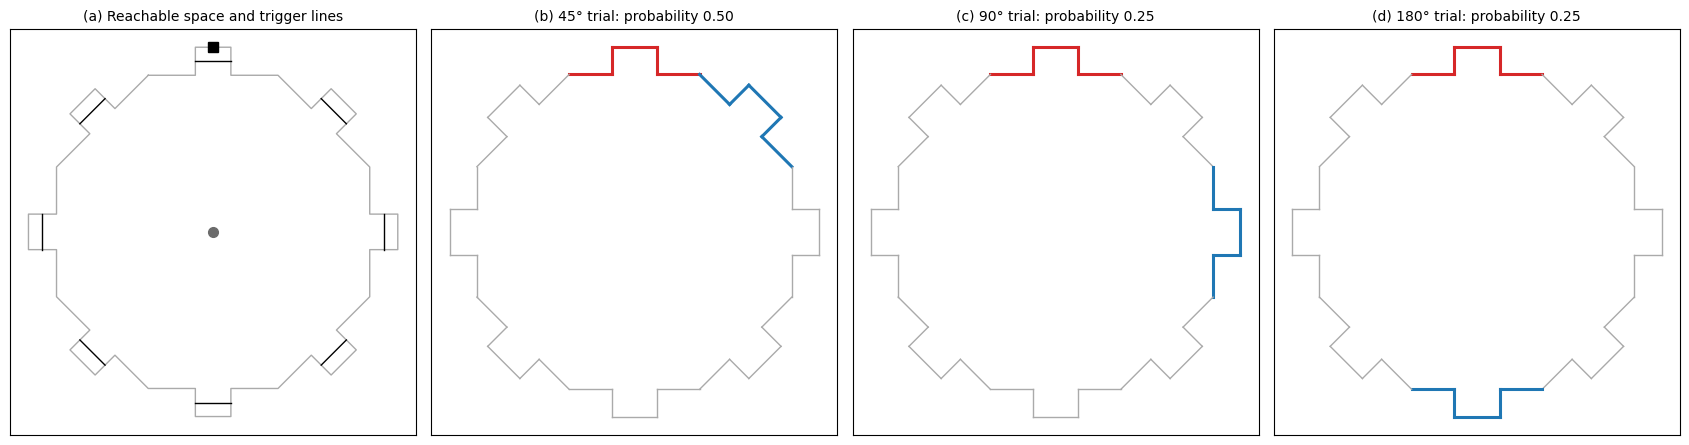

,value,source
input,,
speed (units/s),10.0,moveSpeed in OctagonAgent.cs; logged median 10.0
turning rate (deg/s),331.034561683,median turning rate of central agents before f...
closing speed while turning (units/s),7.572513208,median of central agents (logs); best possible...
trigger line (units from centre),18.247,trigger box front 18.86 less body radius 0.61
overhead per trial (s),7.092406061,whole trial less slice onset to trigger (logs)
ray sensor,"7 rays, ±55 deg",SelectivePassThroughRaycast (agent_raycast.py)


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
ax = axes[0]
poly = np.vstack([ar.reach_polygon(), ar.reach_polygon()[:1]])
ax.plot(poly[:, 0], poly[:, 1], color=C_WALL, lw=1)
for w in range(ar.NUM_WALLS):
    a_, b_ = ar._pt(ar.TRIGGER_REACH, -ar.H, w), ar._pt(ar.TRIGGER_REACH, ar.H, w)
    ax.plot([a_[0], b_[0]], [a_[1], b_[1]], color='black', lw=1)
ax.plot(0, 0, 'o', color=C_CENTRAL, ms=7); ax.plot(*BACK, 'ks', ms=7)
ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
ax.set_title('(a) Reachable space and trigger lines', fontsize=10)
lay_tab = ar.layout_table()
for ax, (lab, h, l) in zip(axes[1:], (('(b) 45° trial', 0, 1), ('(c) 90° trial', 0, 2), ('(d) 180° trial', 0, 4))):
    draw_arena(ax, h, l)
    sep = ((l - h) % 8)
    p_type = lay_tab.loc[lay_tab['sep'] == min(sep, 8 - sep), 'prob'].sum()
    ax.set_title(f'{lab}: probability {p_type:.2f}', fontsize=10)
plt.tight_layout(); plt.show()

inputs = pd.DataFrame([
    ('speed (units/s)', ar.SPEED, 'moveSpeed in OctagonAgent.cs; logged median 10.0'),
    ('turning rate (deg/s)', ROT, 'median turning rate of central agents before facing High (logs)'),
    ('closing speed while turning (units/s)', CLOSE, 'median of central agents (logs); best possible 9.46'),
    ('trigger line (units from centre)', ar.TRIGGER_REACH, 'trigger box front 18.86 less body radius 0.61'),
    ('overhead per trial (s)', OVERHEAD, 'whole trial less slice onset to trigger (logs)'),
    ('ray sensor', '7 rays, ±55 deg', 'SelectivePassThroughRaycast (agent_raycast.py)'),
], columns=['input', 'value', 'source']).set_index('input')
display(inputs)

## 2. Step 1: geometry only

**Motivation.** The simplest version asks what the peripheral position is worth if both agents knew both lit walls at onset and set off along their shortest paths at once.

**Method.** The central agent goes straight to High from the centre (18.25 units, 1.82 s). The peripheral agent follows a rule. "Closest" goes to the wall with the shorter path. The threshold rule goes to Low only if High is more than Δ seconds further than Low (Δ = 0 is closest, Δ ≥ 3.8 s is always High). Paths bend only at the alcove mouth corners.

**Terms.** Walls from own alcove: how many walls from the peripheral agent's alcove to a wall (0 = own, 4 = opposite).

**How to read the figure.** (a) Shortest paths from an alcove back to walls 1-4 away (coloured, with their lengths) and the central agent's path (orange). (b) Path length by walls from own alcove; the dashed line is the central agent's path. (c) Score per second against Δ for the peripheral agent (blue) and the central agent (grey), with the best Δ marked.

**Why it is plotted.** A peripheral agent can only win a wall it reaches before the central agent, so (b) shows which walls it can win. (c) shows how the choice threshold trades Low wins against High wins.

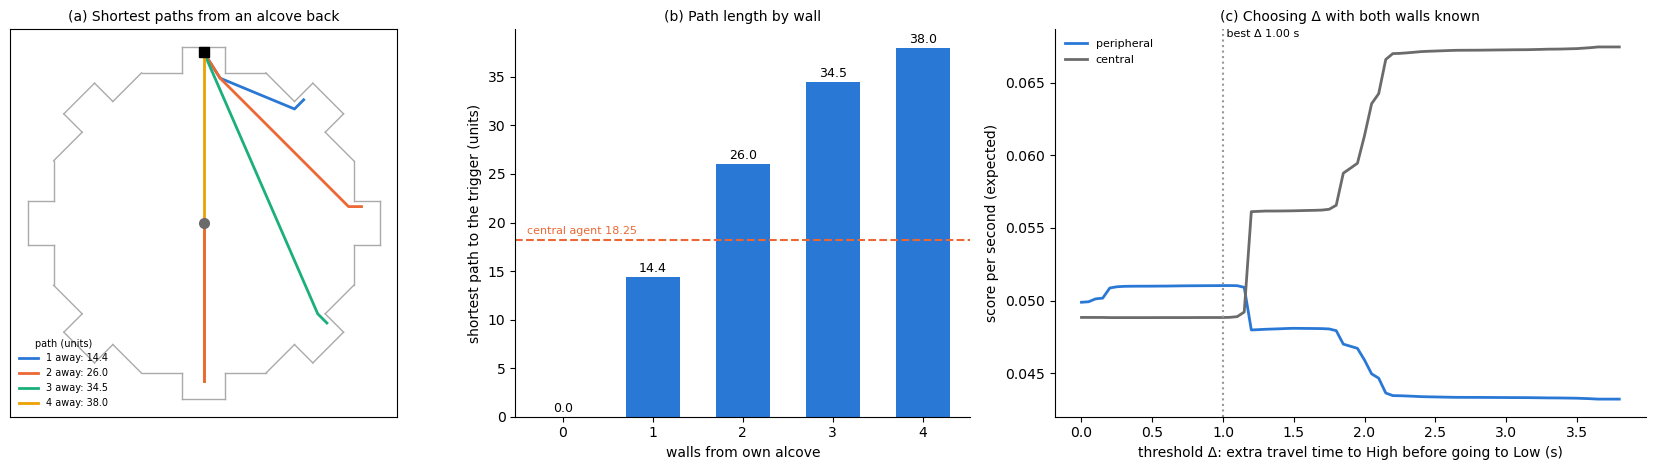

,peripheral score/s,central score/s,margin,peripheral score/trial,central score/trial,peripheral win share,ends at Low,race (s)
always High,0.0432,0.0675,-0.0243,0.3630,0.5669,0.4331,0.1167,1.3097
closest (Δ = 0),0.0499,0.0488,0.0010,0.4153,0.4066,0.5934,0.5000,1.2345
best Δ = 1.00 s,0.0510,0.0488,0.0022,0.4251,0.4067,0.5933,0.3114,1.2376
central vs central,0.0561,0.0561,0.0000,0.5000,0.5000,0.5000,0.0000,1.8247


In [5]:
d_back = ar.path_lengths(BACK[None])[0]
d_centre = ar.TRIGGER_REACH
sweep0 = pd.DataFrame([dict(delta=d, **summary(with_times(D_KNOWN[pi_, hi_] / ar.SPEED, D_KNOWN[pi_, lo_] / ar.SPEED, GAP_KNOWN > d),
                                               'low_first', central_t=CT_STRAIGHT)) for d in D_GRID])
D_BEST0 = float(sweep0.loc[sweep0['peripheral score/s'].idxmax(), 'delta'])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw=dict(width_ratios=[1, 1, 1.3]))
ax = axes[0]
draw_arena(ax)
for off, col in zip((1, 2, 3, 4), ('#2a78d6', '#eb6834', '#1baf7a', '#eda100')):
    p = ar.path_points(BACK, off)
    ax.plot(p[:, 0], p[:, 1], color=col, lw=2, label=f'{off} away: {d_back[off]:.1f}')
draw_central(ax, 4)
ax.plot(*BACK, 'ks', ms=7)
ax.legend(loc='lower left', fontsize=7, frameon=False, title='path (units)', title_fontsize=7)
ax.set_title('(a) Shortest paths from an alcove back', fontsize=10)
ax = axes[1]
offs = np.arange(5)
ax.bar(offs, d_back[[0, 1, 2, 3, 4]], color=C_PERIPH, width=0.6)
for x, v in zip(offs, d_back[[0, 1, 2, 3, 4]]):
    ax.text(x, v + 0.5, f'{v:.1f}', ha='center', fontsize=9)
ax.axhline(d_centre, color=C_ROUTE_C, ls='--', lw=1.5)
ax.text(-0.4, d_centre + 0.6, f'central agent {d_centre:.2f}', color=C_ROUTE_C, fontsize=8)
ax.set_xlabel('walls from own alcove'); ax.set_ylabel('shortest path to the trigger (units)')
ax.set_title('(b) Path length by wall', fontsize=10)
ax.spines[['top', 'right']].set_visible(False)
ax = axes[2]
ax.plot(sweep0['delta'], sweep0['peripheral score/s'], color=C_PERIPH, lw=2, label='peripheral')
ax.plot(sweep0['delta'], sweep0['central score/s'], color=C_CENTRAL, lw=2, label='central')
ax.axvline(D_BEST0, color='#999999', ls=':', lw=1.5)
ax.text(D_BEST0, ax.get_ylim()[1], f' best Δ {D_BEST0:.2f} s', va='top', fontsize=8)
ax.set_xlabel('threshold Δ: extra travel time to High before going to Low (s)')
ax.set_ylabel('score per second (expected)')
ax.legend(frameon=False, fontsize=8)
ax.set_title('(c) Choosing Δ with both walls known', fontsize=10)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

step1 = pd.DataFrame({
    'always High': summary(with_times(D_KNOWN[pi_, hi_] / 10, D_KNOWN[pi_, lo_] / 10, np.zeros(len(pooled), bool)), 'low_first'),
    'closest (Δ = 0)': summary(with_times(D_KNOWN[pi_, hi_] / 10, D_KNOWN[pi_, lo_] / 10, GAP_KNOWN > ar.TIE), 'low_first'),
    f'best Δ = {D_BEST0:.2f} s': summary(with_times(D_KNOWN[pi_, hi_] / 10, D_KNOWN[pi_, lo_] / 10, GAP_KNOWN > D_BEST0), 'low_first')}).T
step1.loc['central vs central'] = [ref_score(CT_STRAIGHT), ref_score(CT_STRAIGHT), 0, 0.5, 0.5, 0.5, 0, ar.TRIGGER_REACH / 10]
display(step1.round(4))

**How to read the table** (used for every step). One row per peripheral rule, against the same central agent, then central vs central. Ends at Low is the share of trials the peripheral agent's race ends at Low, including instant wins (an agent standing on a lit trigger at onset wins it at once).

## 3. Step 2: the central agent senses with rays

**Motivation.** A real agent does not know where High is at onset: it senses walls with 7 rays and must turn to find and face High. This step gives the central agent that limit.

**Method.**
1. The central agent's heading at onset is uniform at random. Its 7 rays (0, ±18.3, ±36.7, ±55° from the heading) sense any part of a lit wall they hit first. From the centre, High is sensed when it is within 77.5° of the heading.
2. If High is sensed, it turns the short way to face it. If not, it turns in place in the direction that should find High sooner (inference from the walls it sees, step 5), or at random on a tie.
3. Once High is sensed it keeps turning to face it (331°/s), closing on it at 7.57 units/s, then travels straight at 10 units/s.

**Terms.** Central time: slice onset to reaching High's trigger (s).

**How to read the figure.** (a) A central agent facing away from High (red) with Low (blue) in view: its rays (black), the arc it turns (orange, labelled with the direction), then its route. (b) The distribution of the central agent's time to High over headings and layouts, with straight travel (1.82 s) and the mean marked.

**Why it is plotted.** The central agent's time is what the peripheral agent races against. Sensing makes it slower and more variable.

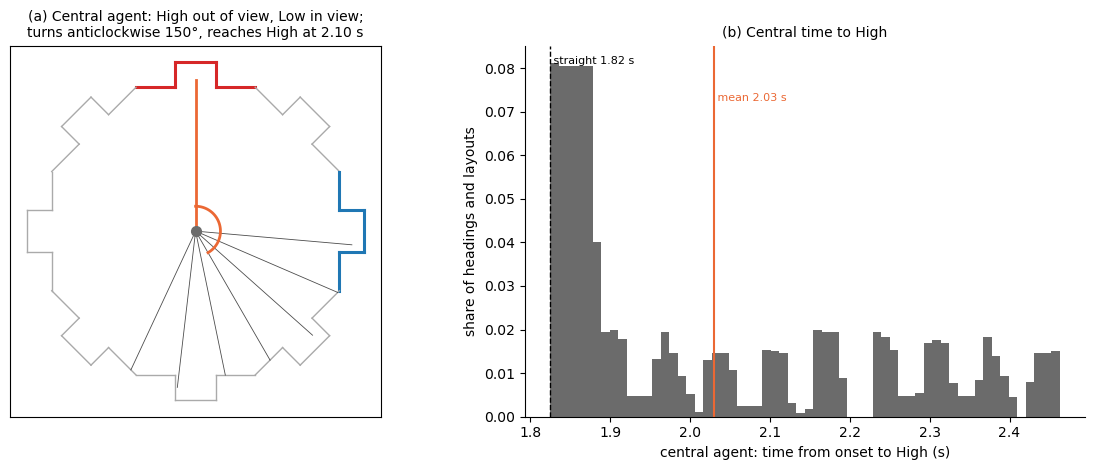

,peripheral score/s,central score/s,margin,peripheral score/trial,central score/trial,peripheral win share,ends at Low,race (s)
"best Δ (step 1), straight central",0.0510,0.0488,0.0022,0.4251,0.4067,0.5933,0.3114,1.2376
"best Δ (step 1), central with rays",0.0507,0.0482,0.0026,0.4266,0.4050,0.5950,0.3114,1.3183
"central vs central, with rays",0.0555,0.0555,0.0000,0.5000,0.5000,0.5000,0.0000,1.9206


In [6]:
h_ex, low_rel_ex = 150.0, 2                  # heading, and Low two walls clockwise of High (High at wall 0)
t_ex, d_ex = ar.central_time_one(h_ex, low_rel_ex, ROT, CLOSE)
ct_all = np.concatenate([v for v in CT_INF.values()])
ct_w = np.concatenate([np.full(len(v), ar.low_offset_weights()[k] / len(v)) for k, v in CT_INF.items()])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
draw_arena(ax, 0, low_rel_ex)
draw_rays(ax, np.zeros(2), h_ex)
turn = (d_ex * (0 - h_ex)) % 360
arc = np.radians(h_ex + d_ex * np.linspace(0, turn, 60))
ax.plot(3 * np.sin(arc), 3 * np.cos(arc), color=C_ROUTE_C, lw=2)
draw_central(ax, 0)
ax.set_title(f"(a) Central agent: High out of view, Low in view;\nturns {'clockwise' if d_ex == 1 else 'anticlockwise'} "
             f"{turn:.0f}°, reaches High at {t_ex:.2f} s", fontsize=10)
ax = axes[1]
ax.hist(ct_all, bins=60, weights=ct_w, color=C_CENTRAL)
ct_mean_all = float((ct_all * ct_w).sum())
ax.axvline(ar.TRIGGER_REACH / ar.SPEED, color='black', ls='--', lw=1)
ax.axvline(ct_mean_all, color=C_ROUTE_C, lw=1.5)
ax.text(ar.TRIGGER_REACH / ar.SPEED, ax.get_ylim()[1] * 0.95, ' straight 1.82 s', fontsize=8)
ax.text(ct_mean_all, ax.get_ylim()[1] * 0.85, f' mean {ct_mean_all:.2f} s', fontsize=8, color=C_ROUTE_C)
ax.set_xlabel('central agent: time from onset to High (s)'); ax.set_ylabel('share of headings and layouts')
ax.set_title('(b) Central time to High', fontsize=10)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

step2 = pd.DataFrame({
    f'best Δ (step 1), straight central': step1.loc[f'best Δ = {D_BEST0:.2f} s'],
    f'best Δ (step 1), central with rays': summary(with_times(D_KNOWN[pi_, hi_] / 10, D_KNOWN[pi_, lo_] / 10, GAP_KNOWN > D_BEST0),
                                                    'low_first', central_t=CT_INF)}).T
step2.loc['central vs central, with rays'] = [ref_score(CT_INF), ref_score(CT_INF), 0, 0.5, 0.5, 0.5, 0,
                                              ar.central_reference(OVERHEAD, central_t=CT_INF)['race_s']]
display(step2.round(4))

## 4. Step 3: the peripheral agent senses with rays

**Motivation.** From inside its alcove the peripheral agent's rays are blocked by the alcove walls, so it often cannot see the walls next to it, which are the ones it can win.

**Method.**
1. The peripheral agent senses with the same 7 rays, from its logged onset position and heading.
2. A wall its rays hit at onset is known: it turns onto the first stretch of its shortest path while closing along it (7.57 units/s), then follows the path at 10 units/s, turning to face each new stretch at bends while still moving.
3. A wall not sensed at onset must be found: the agent moves out of its alcove toward the centre and turns at the same time (turning and moving are separate controls) until a ray hits it.

**Terms.** Sensed at onset: a ray hits the wall at the onset heading. Search time: onset until a ray first hits the wall.

**How to read the figure.** (a) Rays at onset from an alcove back facing out: the far Low is hit, the adjacent High is not. (b) The search for the hidden High: moving out while turning (dashed), the point where High is sensed (red dot, with the rays then), and the path (solid). (c) Share of agent-trials with a wall sensed at onset, by walls from own alcove. (d) Mean time to a wall with rays (bars) and with the wall known at onset (dots); the dashed line is the central agent's mean.

**Why it is plotted.** (c) and (d) show which walls the alcove hides and what finding them costs.

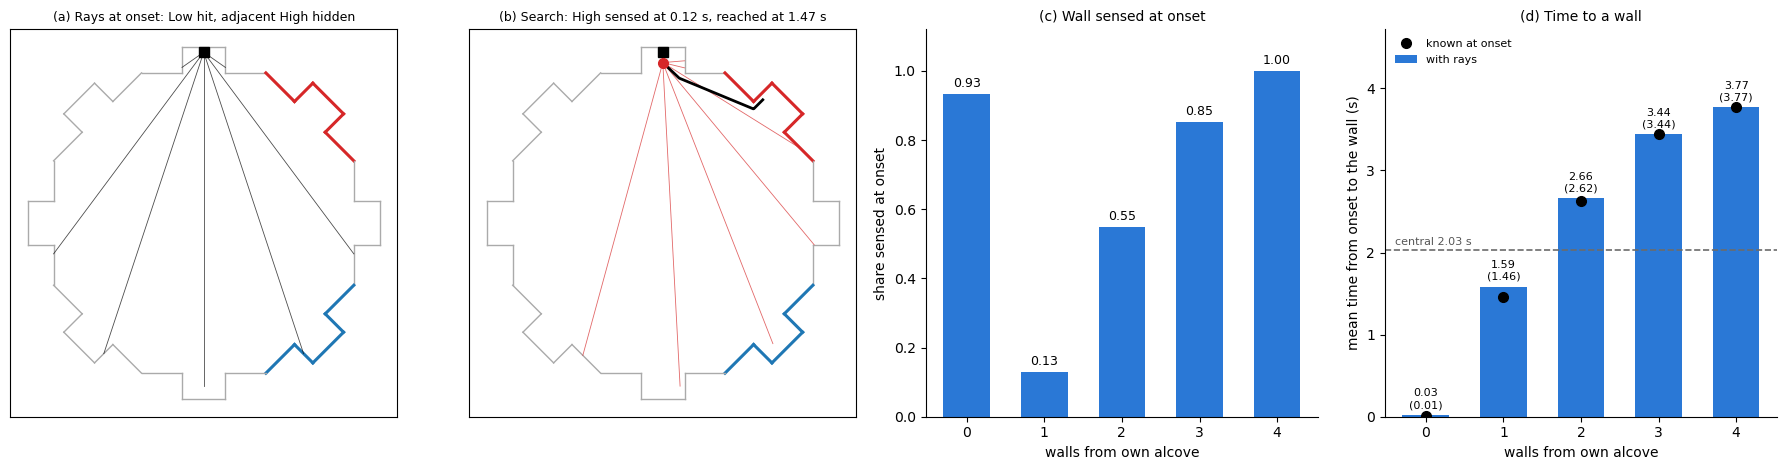

,peripheral score/s,central score/s,margin,peripheral score/trial,central score/trial,peripheral win share,ends at Low,race (s)
"best Δ, walls known, sets off at once",0.0507,0.0482,0.0026,0.4266,0.4050,0.5950,0.3114,1.3183
"best Δ, walls known, turns onto its path",0.0506,0.0481,0.0025,0.4263,0.4053,0.5947,0.3114,1.3271
"best Δ, chosen wall found with rays (not playable)",0.0490,0.0500,-0.0011,0.4137,0.4228,0.5772,0.3114,1.3571


In [7]:
hg, lw_ = 1, 3                                # adjacent High, Low three walls away
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
ax = axes[0]
draw_arena(ax, hg, lw_); draw_rays(ax, BACK, H_OUT); ax.plot(*BACK, 'ks', ms=7)
ax.set_title('(a) Rays at onset: Low hit, adjacent High hidden', fontsize=9)
ax = axes[1]
draw_arena(ax, hg, lw_)
d_good = 1 if ar.step_search_trace(BACK, H_OUT, 1, ROT)['first'][hg] <= ar.step_search_trace(BACK, H_OUT, -1, ROT)['first'][hg] else -1
tr = ar.high_trace(BACK, H_OUT, hg, d_good, ROT, CLOSE)
ax.plot(*route_xy(tr['state'], 0, tr['sensed']).T, color='black', ls='--', lw=1.5)
qs, hs = tr['state'](tr['sensed'])
draw_rays(ax, qs, hs, color=C_HIGHW)
ax.plot(*route_xy(tr['state'], tr['sensed'], tr['arrive']).T, color='black', lw=2)
ax.plot(*BACK, 'ks', ms=7); ax.plot(*qs, 'o', color=C_HIGHW, ms=7)
ax.set_title(f"(b) Search: High sensed at {tr['sensed']:.2f} s, reached at {tr['arrive']:.2f} s", fontsize=9)
by_off = pooled.assign(off=pooled['high_off'].abs()).groupby('off').apply(lambda g: pd.Series(dict(
    sensed0=np.average(g['high_sensed0'], weights=g['prob']),
    t_rays=np.average(g['t_high'], weights=g['prob']))), include_groups=False)
by_off['t_known'] = pd.Series(np.average(T_KNOWN[pi_, hi_], weights=W_PROB)).reindex(by_off.index)
tk = pd.DataFrame(dict(off=pooled['high_off'].abs(), t=T_KNOWN[pi_, hi_], w=W_PROB)).groupby('off').apply(
    lambda g: np.average(g['t'], weights=g['w']), include_groups=False)
ax = axes[2]
ax.bar(by_off.index, by_off['sensed0'], color=C_PERIPH, width=0.6)
for x, v in zip(by_off.index, by_off['sensed0']):
    ax.text(x, v + 0.02, f'{v:.2f}', ha='center', fontsize=9)
ax.set_ylim(0, 1.12); ax.set_xlabel('walls from own alcove'); ax.set_ylabel('share sensed at onset')
ax.set_title('(c) Wall sensed at onset', fontsize=10); ax.spines[['top', 'right']].set_visible(False)
ax = axes[3]
ax.bar(by_off.index, by_off['t_rays'], color=C_PERIPH, width=0.6, label='with rays')
ax.plot(tk.index, tk.values, 'o', color='black', ms=7, label='known at onset')
for x, v, k in zip(by_off.index, by_off['t_rays'], tk.values):
    ax.text(x, v + 0.08, f'{v:.2f}\n({k:.2f})', ha='center', fontsize=8)
ct_mean = sum(ar.low_offset_weights()[k] * CT_INF[k].mean() for k in CT_INF)
ax.axhline(ct_mean, color=C_CENTRAL, ls='--', lw=1.2)
ax.text(-0.4, ct_mean + 0.06, f'central {ct_mean:.2f} s', fontsize=8, color='#555555')
ax.set_ylim(0, by_off['t_rays'].max() * 1.25)
ax.set_xlabel('walls from own alcove'); ax.set_ylabel('mean time from onset to the wall (s)')
ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_title('(d) Time to a wall', fontsize=10); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

# score the best step-1 choice with each extra limit: turning onto the path, then finding the chosen wall
step3 = pd.DataFrame({
    'best Δ, walls known, sets off at once': step2.iloc[1],
    'best Δ, walls known, turns onto its path': summary(with_times(T_KNOWN[pi_, hi_], T_KNOWN[pi_, lo_], GAP_KNOWN > D_BEST0),
                                                         'low_first', central_t=CT_INF),
    'best Δ, chosen wall found with rays (not playable)': summary(with_times(pooled_inf['t_high'], pooled_inf['t_low'], GAP_KNOWN > D_BEST0),
                                                                  'low_first', central_t=CT_INF)}).T
display(step3.round(4))

**How to read the table.** The best step-1 choice (Δ chosen with both walls known), against the central agent with rays, as each limit is added. The last row still chooses the wall from both walls' true positions at onset, which the agent cannot know; it is shown only to isolate the cost of finding the chosen wall.

## 5. Step 4: choosing a wall from partial knowledge

**Motivation.** With rays, the peripheral agent may know only one lit wall, or none, when it has to act. A rule may only use what has been sensed.

**Method.** Three rules, with the search direction chosen at random:
- *High, always*: search for High if needed, then go to it.
- *Low if seen first*: go to whichever lit wall a ray hits first (both at once goes High).
- *Nearest once both sensed*: head for High until both walls have been sensed, then go to the one with the shorter remaining path.

**How to read the figure.** Two example layouts for the agent at an alcove back. (a) "Low if seen first": the far Low is hit first, so the agent goes there (solid), giving up the hidden adjacent High it would reach on the dashed route. (b) "Nearest": the agent sets off for a High two walls away (dashed), sees the adjacent Low as it leaves the alcove (star), and switches (solid). Titles give times and the central agent's mean.

**Why it is plotted.** It shows why committing to the first wall seen fails from an alcove, and why waiting to compare both walls works.

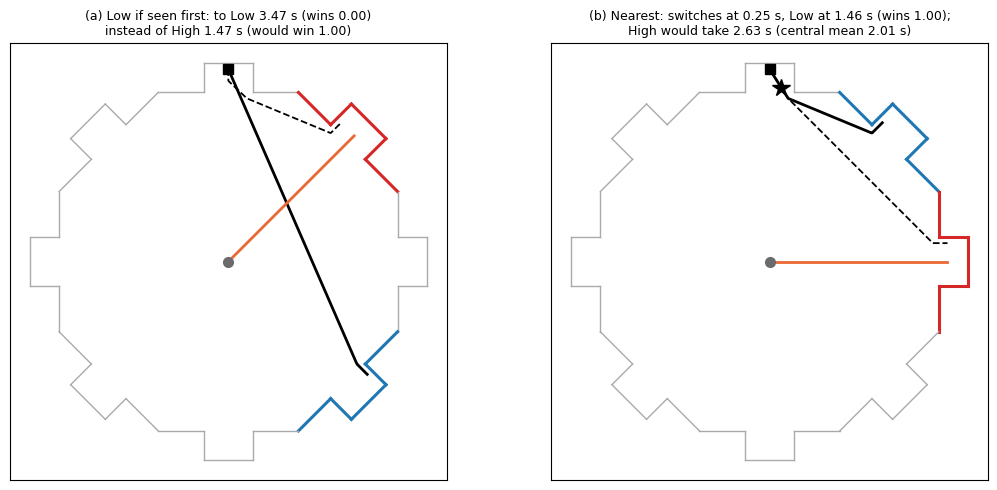

,peripheral score/s,central score/s,margin,peripheral score/trial,central score/trial,peripheral win share,ends at Low,race (s)
"High, always",0.0416,0.0672,-0.0257,0.3552,0.5747,0.4253,0.1167,1.4548
Low if seen first,0.0267,0.0792,-0.0525,0.2301,0.6814,0.3186,0.3566,1.5106
Nearest once both sensed,0.0469,0.0541,-0.0072,0.3979,0.4586,0.5414,0.4256,1.3894
central vs central,0.0555,0.0555,0.0000,0.5000,0.5000,0.5000,0.0000,1.9206


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
# (a) Low if seen first: far Low seen at onset, adjacent High hidden
ax = axes[0]
hg, lw_ = 1, 3
draw_arena(ax, hg, lw_)
tr_h = ar.high_trace(BACK, H_OUT, hg, d_good, ROT, CLOSE)
tr_l = ar.known_trace(BACK, H_OUT, lw_, ROT, CLOSE)
ax.plot(*route_xy(tr_h['state'], 0, tr_h['arrive']).T, color='black', ls='--', lw=1.3)
ax.plot(*route_xy(tr_l['state'], 0, tr_l['arrive']).T, color='black', lw=2)
draw_central(ax, hg); ax.plot(*BACK, 'ks', ms=7)
ax.set_title(f"(a) Low if seen first: to Low {tr_l['arrive']:.2f} s (wins {win_share(tr_l['arrive'], hg, lw_, CT_INF):.2f})\n"
             f"instead of High {tr_h['arrive']:.2f} s (would win {win_share(tr_h['arrive'], hg, lw_, CT_INF):.2f})", fontsize=9)
# (b) nearest: heads for High two away, sees the adjacent Low, switches
ax = axes[1]
hg, lw_ = 2, 1
draw_arena(ax, hg, lw_)
tr = ar.high_trace(BACK, H_OUT, hg, 1, ROT, CLOSE)
first = ar.trace_first_sensed(tr)
t_dec = max(tr['sensed'], first[lw_])
q, hh = tr['state'](t_dec)
lt = ar.known_trace(q, hh, lw_, ROT, CLOSE)
ax.plot(*route_xy(tr['state'], 0, tr['arrive']).T, color='black', ls='--', lw=1.3)
ax.plot(*route_xy(tr['state'], 0, t_dec).T, color='black', lw=2)
ax.plot(*route_xy(lt['state'], 0, lt['arrive']).T, color='black', lw=2)
ax.plot(*q, '*', color='black', ms=13)
draw_central(ax, hg); ax.plot(*BACK, 'ks', ms=7)
ax.set_title(f"(b) Nearest: switches at {t_dec:.2f} s, Low at {t_dec + lt['arrive']:.2f} s (wins "
             f"{win_share(t_dec + lt['arrive'], hg, lw_, CT_INF):.2f});\nHigh would take {tr['arrive']:.2f} s "
             f"(central mean {CT_INF[(lw_ - hg) % 8].mean():.2f} s)", fontsize=9)
plt.tight_layout(); plt.show()

step4 = pd.DataFrame({lab: summary(pooled, pol, central_t=CT_INF) for lab, pol in
                      (('High, always', 'high'), ('Low if seen first', 'low_first'), ('Nearest once both sensed', 'nearest'))}).T
step4.loc['central vs central'] = [ref_score(CT_INF), ref_score(CT_INF), 0, 0.5, 0.5, 0.5, 0,
                                   ar.central_reference(OVERHEAD, central_t=CT_INF)['race_s']]
display(step4.round(4))

## 6. Step 5: inferring where unseen walls are

**Motivation.** What the rays have sensed narrows down where an unseen wall can be: an unlit wall cannot be lit, and Low is always 1, 2 or 4 walls from High. An agent can use this to search the right way, and to judge an unseen wall's distance.

**Method.** The agent combines the layout rules with every wall sensed so far into a probability for each (High, Low) layout (`ar.joint_posterior`). If the wall it wants is unseen, it searches in the direction with the lower expected time until a ray hits it.

**Terms.** Probability of High (or Low) at a wall: the share of the remaining layouts, weighted by their prior, with that wall lit as High (or Low).

**How to read the figure.** Walls shaded by probability (darker = more likely; grey = ruled out), for the agent at an alcove back facing out; the dotted wall is the one seen, and the thin lines are the rays at onset. (a) High three walls away is seen; where could Low be? (b) The far Low is seen and the adjacent High is hidden; where could High be? (c) Mean search time for a hidden High, with a random and an inferred search direction.

**Why it is plotted.** (a) and (b) show what the agent can work out from one sensed wall. (c) shows how much that speeds up its search.

**How to read the table.** As in step 4, with inferred search directions.

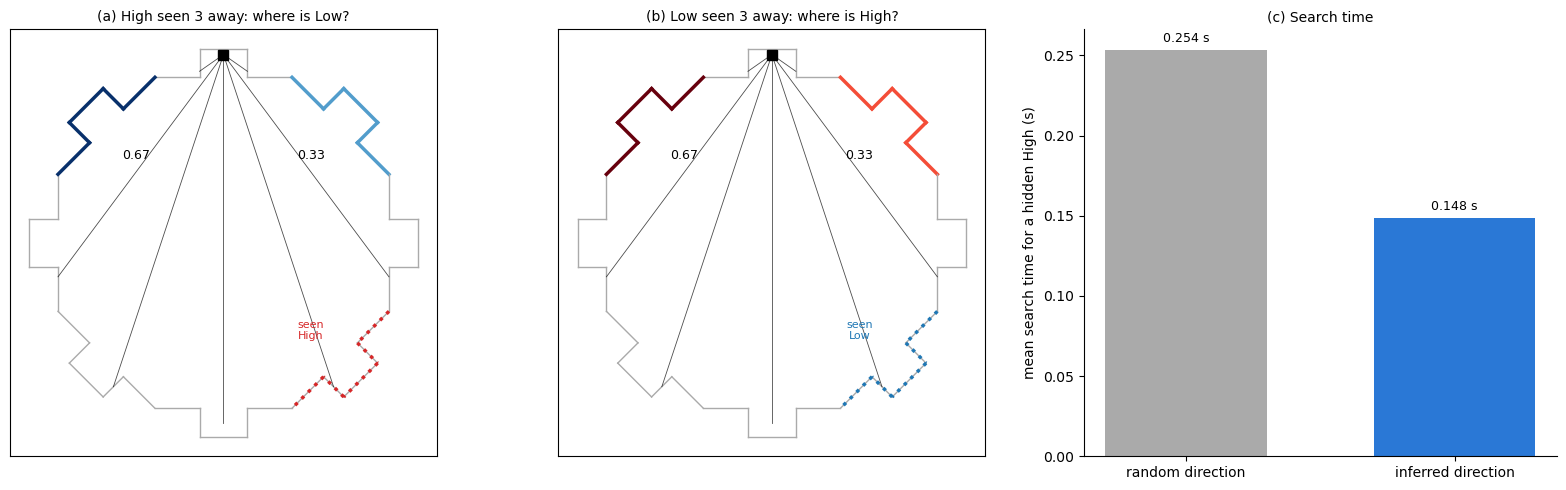

,peripheral score/s,central score/s,margin,peripheral score/trial,central score/trial,peripheral win share,ends at Low,race (s)
"High, always",0.0416,0.0673,-0.0257,0.3552,0.5748,0.4252,0.1167,1.4428
Low if seen first,0.0251,0.0815,-0.0564,0.2161,0.7014,0.2986,0.3565,1.5183
Nearest once both sensed,0.0469,0.0541,-0.0072,0.3974,0.4583,0.5417,0.4262,1.3733


In [9]:
S_back = ar.onset_sensed(BACK[None], [H_OUT])[0]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (hg, lw_, which, lab) in zip(axes[:2], ((3, 1, 'low', '(a) High seen 3 away: where is Low?'),
                                                 (1, 3, 'high', '(b) Low seen 3 away: where is High?'))):
    J = ar.joint_posterior(S_back, hg if S_back[hg] else None, lw_ if S_back[lw_] else None)
    prob = J.sum(axis=0) if which == 'low' else J.sum(axis=1)
    draw_arena(ax, shade=prob / prob.max(), cmap='Blues' if which == 'low' else 'Reds')
    seen_w = hg if which == 'low' else lw_
    for (a_, b_), w in zip(WALL_SEGS, WALL_IDS):
        if w == seen_w:
            ax.plot([a_[0], b_[0]], [a_[1], b_[1]], color=C_HIGHW if which == 'low' else C_LOWW, lw=2.5, ls=':')
    for w in range(8):
        if prob[w] > 0:
            p_ = ar._pt(13.0, 0.0, w)
            ax.text(p_[0], p_[1], f'{prob[w]:.2f}', ha='center', va='center', fontsize=9)
    p_ = ar._pt(13.0, 0.0, seen_w)
    ax.text(p_[0], p_[1], 'seen\nHigh' if which == 'low' else 'seen\nLow', ha='center', va='center', fontsize=8,
            color=C_HIGHW if which == 'low' else C_LOWW)
    draw_rays(ax, BACK, H_OUT); ax.plot(*BACK, 'ks', ms=7)
    ax.set_title(lab, fontsize=10)
hidden = ~pooled['high_sensed0']
search = pd.Series({'random direction': np.average(pooled.loc[hidden, 'high_tsense'], weights=pooled.loc[hidden, 'prob']),
                    'inferred direction': np.average(pooled_inf.loc[hidden, 'high_tsense'], weights=pooled_inf.loc[hidden, 'prob'])})
ax = axes[2]
ax.bar(range(2), search.values, color=[C_WALL, C_PERIPH], width=0.6)
for x, v in enumerate(search.values):
    ax.text(x, v + 0.005, f'{v:.3f} s', ha='center', fontsize=9)
ax.set_xticks(range(2), search.index); ax.set_ylabel('mean search time for a hidden High (s)')
ax.set_title('(c) Search time', fontsize=10); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

step5 = pd.DataFrame({lab: summary(pooled_inf, pol, central_t=CT_INF) for lab, pol in
                      (('High, always', 'high'), ('Low if seen first', 'low_first'), ('Nearest once both sensed', 'nearest'))}).T
display(step5.round(4))

## 7. Step 6: the Δ rule with inference about both walls

**Motivation.** The best rule in step 1 was a threshold. With inference, the agent can apply it even to a wall it has not yet seen, using that wall's expected distance, and so pick the walls it is more likely to win.

**Method** (`delta2`).
1. At onset and whenever a ray first hits a new wall, the agent works out where both walls could be (step 5).
2. It goes for Low if (distance to High - distance to Low) / 10 units/s > Δ, otherwise High. A sensed wall's distance is its shortest path; an unseen wall's is the expected path over where it could be.
3. If the chosen wall is sensed it goes to it; if not, it searches for it (moving out of its alcove while turning, in the direction that should find it sooner).
4. It re-decides at every new wall and may switch either way.

**How Δ was identified.** Δ is swept from 0 to 3.8 s and the value with the highest peripheral score per second is taken. Each race's outcome is stored as a function of Δ, so the sweep is exact. The choice is checked by choosing Δ on five of the six sets of start positions (each set comes from one trained peripheral model) and scoring it on the sixth.

**How to read the first figure.** Three routes for the agent at an alcove back, at the best Δ. (a) High three walls away is seen; the agent infers Low is probably near its own alcove, searches that way (dashed), sees Low (star) and goes there. (b) A hidden adjacent High with a far Low seen: High is probably near, so it keeps searching for High. (c) Both walls far: it goes for High. Titles give the outcome and times.

**How to read the second figure.** (a) Score per second against Δ for the peripheral agent (blue) and the central agent (grey), with the High-only version of the rule (inference about High only, dashed) and the first model (dotted) for comparison; the best Δ and the range within 0.5% of it are marked. (b) The peripheral margin against Δ. (c) Score per second against Δ for each set of start positions (labelled by the trained model they come from), with each set's own best Δ marked (dots). The rule set is the same; only where the agent starts differs. (d) For each race that ends at Low at small Δ, the Δ above which it no longer does (weighted share of trials): the steps in (a) sit where many races switch together.

**Why it is plotted.** It shows how sharply the result depends on Δ, why the curve has steps, and that the chosen Δ is not tuned to particular start positions.

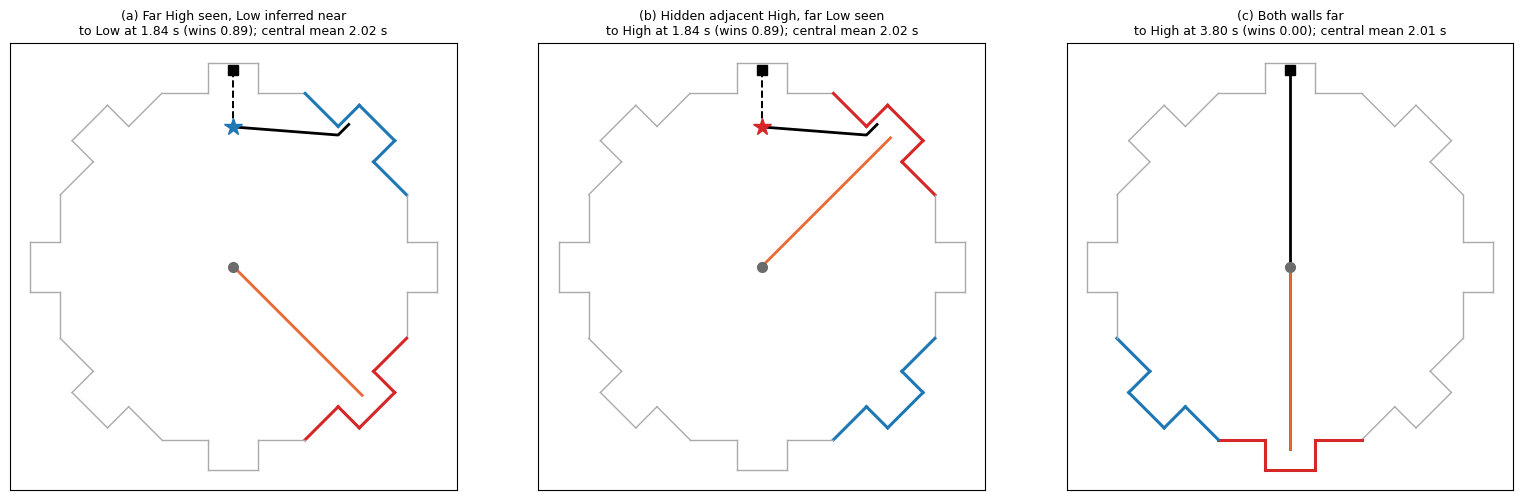

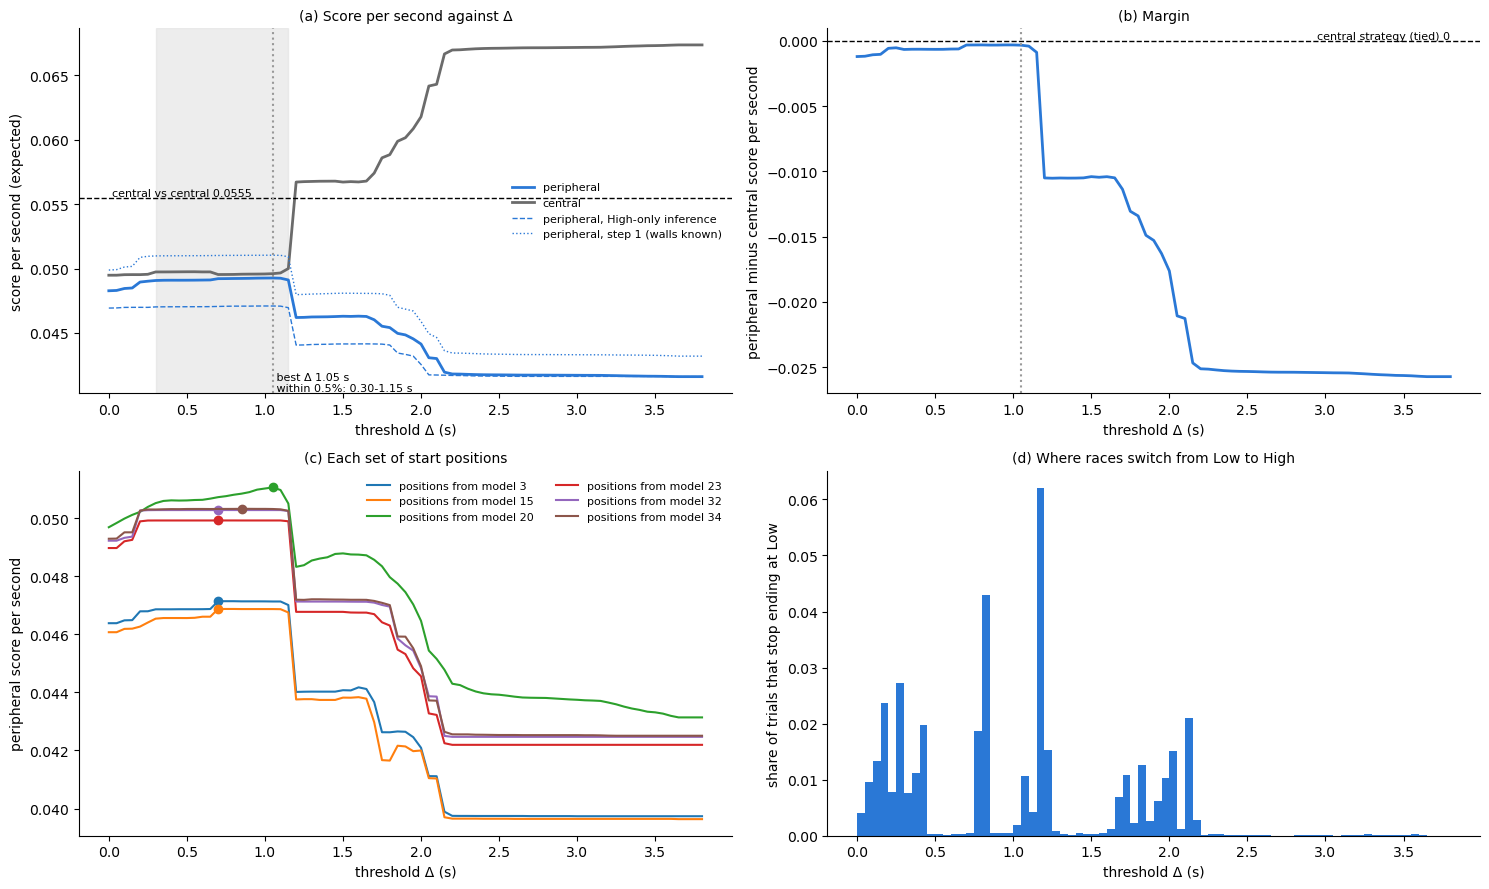

,delta_chosen_on_others,score_at_that_delta,best_score_for_this_model,its_own_best_delta,margin_at_chosen_delta
held_out_positions_from_model,,,,,
3,1.05,0.0471,0.0471,0.70,-0.0046
15,1.05,0.0469,0.0469,0.70,-0.0052
20,0.80,0.0508,0.0511,1.05,0.0029
23,1.05,0.0499,0.0499,0.70,0.0011
32,1.05,0.0503,0.0503,0.70,0.0019
34,1.05,0.0503,0.0503,0.85,0.0019


In [10]:
sweep6 = pd.DataFrame([dict(delta=d, **summary(pooled, 'delta2', d, CT_INF)) for d in D_GRID])
sweep_hi = pd.DataFrame([dict(delta=d, **summary(pooled_inf, 'delta', d, CT_INF)) for d in D_GRID])
D_BEST6 = float(sweep6.loc[sweep6['peripheral score/s'].idxmax(), 'delta'])
top6 = sweep6.loc[sweep6['peripheral score/s'] >= 0.995 * sweep6['peripheral score/s'].max(), 'delta']

# draw three example routes at the best delta
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (hg, lw_, lab) in zip(axes, ((3, 1, '(a) Far High seen, Low inferred near'), (1, 3, '(b) Hidden adjacent High, far Low seen'),
                                      (4, 5, '(c) Both walls far'))):
    draw_arena(ax, hg, lw_)
    r = ar.delta2_route(BACK, H_OUT, hg, lw_, 1, D_BEST6, ROT, CLOSE)
    for state, s0, e, t0, is_search in r['segments']:
        ax.plot(*route_xy(state, s0, e).T, color='black', lw=1.4 if is_search else 2, ls='--' if is_search else '-')
    for t_d, q, to_low in r['decisions'][1:]:
        ax.plot(*q, '*', color=C_LOWW if to_low else C_HIGHW, ms=13)
    draw_central(ax, hg); ax.plot(*BACK, 'ks', ms=7)
    ax.set_title(f"{lab}\nto {'Low' if r['go_low'] else 'High'} at {r['time']:.2f} s (wins {win_share(r['time'], hg, lw_, CT_INF):.2f}); "
                 f"central mean {CT_INF[(lw_ - hg) % 8].mean():.2f} s", fontsize=9)
plt.tight_layout(); plt.show()

# how delta was identified
per_model = pd.concat([ar.summarise(races, OVERHEAD, 'delta2', d, CT_INF).assign(delta=d) for d in D_GRID], ignore_index=True)
HI_ = np.column_stack([pooled[f'd2_hi_{k}'] for k in range(ar.MAX_PIECES)])
LOW_ = np.column_stack([pooled[f'd2_low_{k}'] for k in range(ar.MAX_PIECES)])
# find, per race, the delta above which it stops ending at Low (first piece boundary where Low changes to High)
stop = np.full(len(pooled), np.nan)
for k in range(ar.MAX_PIECES - 1):
    change = (LOW_[:, k] > 0.5) & (LOW_[:, k + 1] < 0.5) & np.isnan(stop)
    stop[change] = HI_[change, k]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
ax = axes[0, 0]
ax.plot(sweep6['delta'], sweep6['peripheral score/s'], color=C_PERIPH, lw=2, label='peripheral')
ax.plot(sweep6['delta'], sweep6['central score/s'], color=C_CENTRAL, lw=2, label='central')
ax.plot(sweep_hi['delta'], sweep_hi['peripheral score/s'], color=C_PERIPH, lw=1, ls='--', label='peripheral, High-only inference')
ax.plot(sweep0['delta'], sweep0['peripheral score/s'], color=C_PERIPH, lw=1, ls=':', label='peripheral, step 1 (walls known)')
ax.axhline(ref_score(CT_INF), color='black', ls='--', lw=1)
ax.text(0.02, ref_score(CT_INF), f'central vs central {ref_score(CT_INF):.4f}', va='bottom', fontsize=8)
ax.axvspan(top6.min(), top6.max(), color='#dddddd', alpha=0.5)
ax.axvline(D_BEST6, color='#999999', ls=':', lw=1.5)
ax.text(D_BEST6, ax.get_ylim()[0], f' best Δ {D_BEST6:.2f} s\n within 0.5%: {top6.min():.2f}-{top6.max():.2f} s', fontsize=8, va='bottom')
ax.set_ylabel('score per second (expected)'); ax.legend(frameon=False, fontsize=8, loc='center right')
ax.set_title('(a) Score per second against Δ', fontsize=10)
ax = axes[0, 1]
ax.plot(sweep6['delta'], sweep6['margin'], color=C_PERIPH, lw=2)
ax.axhline(0, color='black', ls='--', lw=1); ax.text(3.8, 0, 'central strategy (tied) 0', ha='right', va='bottom', fontsize=8)
ax.axvline(D_BEST6, color='#999999', ls=':', lw=1.5)
ax.set_ylabel('peripheral minus central score per second'); ax.set_title('(b) Margin', fontsize=10)
ax = axes[1, 0]
for k, (m_, g) in enumerate(per_model.groupby('group')):
    col = plt.get_cmap('tab10')(k)
    ax.plot(g['delta'], g['periph_score_s'], color=col, lw=1.5, label=f'positions from model {m_}')
    b = g.loc[g['periph_score_s'].idxmax()]
    ax.plot(b['delta'], b['periph_score_s'], 'o', color=col, ms=6)
ax.set_ylabel('peripheral score per second'); ax.legend(frameon=False, fontsize=8, ncol=2)
ax.set_title('(c) Each set of start positions', fontsize=10)
ax = axes[1, 1]
ok = ~np.isnan(stop)
ax.hist(stop[ok], bins=np.arange(0, 3.85, 0.05), weights=W_PROB[ok], color=C_PERIPH)
ax.set_ylabel('share of trials that stop ending at Low'); ax.set_title('(d) Where races switch from Low to High', fontsize=10)
for ax in axes.ravel():
    ax.set_xlabel('threshold Δ (s)'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

# check the choice of delta by leaving one model out
loo = []
for m_ in sorted(races['group'].unique()):
    train = per_model[per_model['group'] != m_].groupby('delta')['periph_score_s'].mean()
    d_tr = float(train.idxmax())
    test = per_model[per_model['group'] == m_].set_index('delta')
    loo.append(dict(held_out_positions_from_model=m_, delta_chosen_on_others=d_tr, score_at_that_delta=test.loc[d_tr, 'periph_score_s'],
                    best_score_for_this_model=test['periph_score_s'].max(), its_own_best_delta=float(test['periph_score_s'].idxmax()),
                    margin_at_chosen_delta=test.loc[d_tr, 'periph_score_s'] - test.loc[d_tr, 'central_score_s']))
display(pd.DataFrame(loo).set_index('held_out_positions_from_model').round(4))

**How to read the table.** Each row leaves out the start positions from one peripheral model, chooses Δ on the other five sets, and scores that Δ on the left-out set, beside the best that set could get with its own best Δ.

## 8. Score rate across the steps and across trial configurations

**Motivation.** This section puts the steps side by side, and shows where in the arena the final model's score comes from.

**Method.** The steps in order (central agent with rays from step 2 onward; each rule at its own best Δ where it has one):
- 1: walls known, both agents go straight (step 1, best Δ).
- 2: + central agent senses with rays and infers its search direction.
- 3: + peripheral agent turns onto its path (walls still known).
- 4: + peripheral agent finds its chosen wall with rays (choice still uses both walls' true positions; not playable).
- 5-7: playable rules with rays and inference: High always; nearest once both sensed; the Δ rule with inference about both walls (best Δ).

**Terms.** Trial type: 45°, 90° or 180° between High and Low. Layout group: where High is relative to the peripheral agent's alcove; instant means the agent starts on a lit trigger.

**How to read the figures.** Figure 1: peripheral (blue) and central (grey) score per second for each step, with central vs central (dashed) for the central agent of that step. Figure 2: peripheral expected score per trial in each layout (High's and Low's walls from own alcove) for step 1, High always, nearest, and the final Δ rule. Figure 3: for the final rule, who wins and at which wall in each layout group (left), and each group's contribution to score per trial (right).

**Why it is plotted.** Figure 1 shows which components cost or gain score. Figures 2 and 3 show which layouts the peripheral agent wins, and why its score stays close to the central agent's.

**How to read the tables.** First: the steps' scores. Second: score per trial by trial type for step 1 and the final rule. Third: wins and score by layout group for the final rule.

,peripheral score/s,central score/s,margin,peripheral score/trial,central score/trial,peripheral win share,ends at Low,race (s)
"1 walls known, straight",0.0510,0.0488,0.0022,0.4251,0.4067,0.5933,0.3114,1.2376
2 + central rays,0.0507,0.0482,0.0026,0.4266,0.4050,0.5950,0.3114,1.3183
3 + peripheral turns onto path,0.0506,0.0481,0.0025,0.4263,0.4053,0.5947,0.3114,1.3271
4 + finds chosen wall (not playable),0.0490,0.0500,-0.0011,0.4137,0.4228,0.5772,0.3114,1.3571
"5 High, always",0.0416,0.0673,-0.0257,0.3552,0.5748,0.4252,0.1167,1.4428
6 nearest once both sensed,0.0469,0.0541,-0.0072,0.3974,0.4583,0.5417,0.4262,1.3733
"7 Δ rule, both walls inferred (Δ 1.05 s)",0.0493,0.0496,-0.0003,0.4159,0.4187,0.5813,0.3089,1.3487


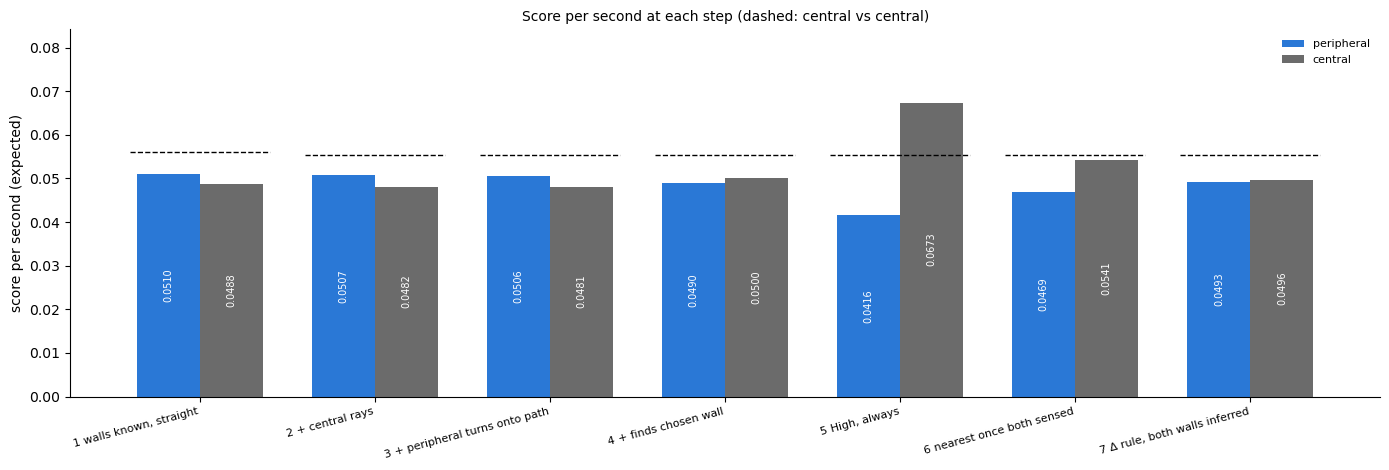

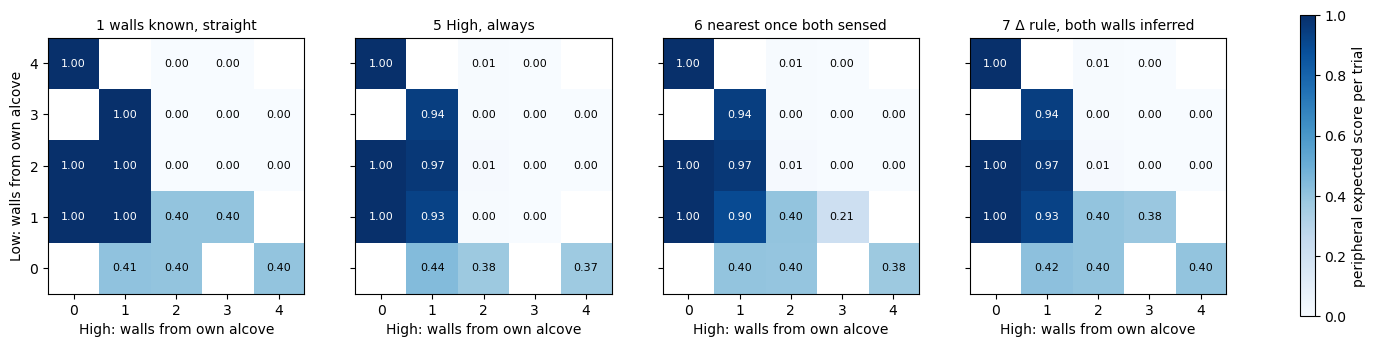

1 walls known, straight                    7 Δ rule, both walls inferred                   
                       share peripheral central                         share peripheral central
t                                                                                               
45°                     0.50      0.351   0.500                          0.50      0.348   0.504
90°                     0.25      0.475   0.375                          0.25      0.452   0.404
180°                    0.25      0.525   0.251                          0.25      0.515   0.263

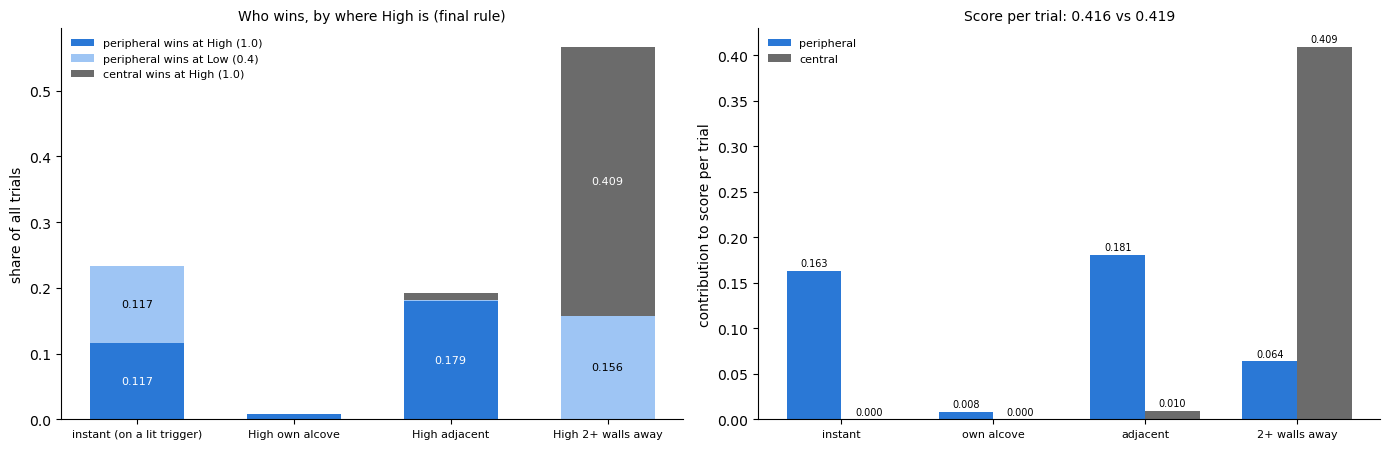

,share of trials,peripheral wins at High,peripheral wins at Low,central wins (High),peripheral score/trial,central score/trial
grp,,,,,,
instant (on a lit trigger),0.233,0.117,0.117,0.000,0.163,0.000
High own alcove,0.008,0.008,0.000,0.000,0.008,0.000
High adjacent,0.192,0.179,0.003,0.010,0.181,0.010
High 2+ walls away,0.567,0.001,0.156,0.409,0.064,0.409
total,1.000,0.306,0.276,0.419,0.416,0.419


In [11]:
steps = pd.DataFrame({
    '1 walls known, straight': step1.loc[f'best Δ = {D_BEST0:.2f} s'],
    '2 + central rays': step2.iloc[1],
    '3 + peripheral turns onto path': step3.iloc[1],
    '4 + finds chosen wall (not playable)': step3.iloc[2],
    '5 High, always': step5.loc['High, always'],
    '6 nearest once both sensed': step5.loc['Nearest once both sensed'],
    f'7 Δ rule, both walls inferred (Δ {D_BEST6:.2f} s)': summary(pooled, 'delta2', D_BEST6, CT_INF)}).T
refs = [ref_score(CT_STRAIGHT)] + [ref_score(CT_INF)] * 6
display(steps.round(4))

fig, ax = plt.subplots(figsize=(14, 4.8))
x = np.arange(len(steps))
ax.bar(x - 0.18, steps['peripheral score/s'], width=0.36, color=C_PERIPH, label='peripheral')
ax.bar(x + 0.18, steps['central score/s'], width=0.36, color=C_CENTRAL, label='central')
for xi, (a_, b_, r_) in enumerate(zip(steps['peripheral score/s'], steps['central score/s'], refs)):
    ax.text(xi - 0.18, a_ / 2, f'{a_:.4f}', ha='center', fontsize=7, rotation=90, va='center', color='white')
    ax.text(xi + 0.18, b_ / 2, f'{b_:.4f}', ha='center', fontsize=7, rotation=90, va='center', color='white')
    ax.plot([xi - 0.4, xi + 0.4], [r_, r_], color='black', ls='--', lw=1)
ax.set_xticks(x, [s.split(' (')[0] for s in steps.index], fontsize=8, rotation=15, ha='right')
ax.set_ylabel('score per second (expected)'); ax.set_ylim(0, steps[['peripheral score/s', 'central score/s']].max().max() * 1.25)
ax.legend(frameon=False, fontsize=8, loc='upper right'); ax.spines[['top', 'right']].set_visible(False)
ax.set_title('Score per second at each step (dashed: central vs central)', fontsize=10)
plt.tight_layout(); plt.show()


def layout_grid(rows, policy, delta=None, central_t=None):
    """ Return the peripheral expected score per trial in each layout (Low row x High column, walls from own alcove). """

    ev = ar.evaluate(rows, policy, delta, central_t)
    g = pd.DataFrame(dict(h=rows['high_off'].abs(), l=rows['low_off'].abs(), w=rows['prob'], s=ev['periph_score']))
    return g.groupby(['l', 'h']).apply(lambda x: np.average(x['s'], weights=x['w']), include_groups=False).unstack().reindex(
        index=range(5), columns=range(5))


grids = [('1 walls known, straight', layout_grid(with_times(D_KNOWN[pi_, hi_] / 10, D_KNOWN[pi_, lo_] / 10, GAP_KNOWN > D_BEST0), 'low_first')),
         ('5 High, always', layout_grid(pooled_inf, 'high', central_t=CT_INF)),
         ('6 nearest once both sensed', layout_grid(pooled_inf, 'nearest', central_t=CT_INF)),
         ('7 Δ rule, both walls inferred', layout_grid(pooled, 'delta2', D_BEST6, CT_INF))]
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6), sharey=True)
for ax, (lab, grid) in zip(axes, grids):
    im = ax.imshow(grid.to_numpy(), origin='lower', cmap='Blues', vmin=0, vmax=1)
    for (li, hi), v in np.ndenumerate(grid.to_numpy()):
        if np.isfinite(v):
            ax.text(hi, li, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if v > 0.6 else 'black')
    ax.set_xticks(range(5)); ax.set_yticks(range(5)); ax.set_xlabel('High: walls from own alcove'); ax.set_title(lab, fontsize=10)
axes[0].set_ylabel('Low: walls from own alcove')
fig.colorbar(im, ax=axes, label='peripheral expected score per trial', shrink=0.85)
plt.show()

# score per trial by trial type, for step 1 and the final rule
def by_type(rows, policy, delta=None, central_t=None):
    """ Return peripheral and central score per trial by trial type (45, 90, 180 degrees). """

    ev = ar.evaluate(rows, policy, delta, central_t)
    t = rows['sep'].map({1: '45°', 2: '90°', 4: '180°'})
    g = pd.DataFrame(dict(t=t, w=rows['prob'], p=ev['periph_score'], c=ev['central_score']))
    return g.groupby('t').apply(lambda x: pd.Series(dict(share=x['w'].sum(), peripheral=np.average(x['p'], weights=x['w']),
                                                         central=np.average(x['c'], weights=x['w']))), include_groups=False)


types = pd.concat({'1 walls known, straight': by_type(with_times(D_KNOWN[pi_, hi_] / 10, D_KNOWN[pi_, lo_] / 10, GAP_KNOWN > D_BEST0), 'low_first'),
                   '7 Δ rule, both walls inferred': by_type(pooled, 'delta2', D_BEST6, CT_INF)}, axis=1).reindex(['45°', '90°', '180°'])
display(types.round(3))

# who wins, at which wall, by where High is (final rule)
ev7 = ar.evaluate(pooled, 'delta2', D_BEST6, CT_INF)
inst = ((pooled['t_high'] == 0) | (pooled['t_low'] == 0)).to_numpy()
low7 = ends_at_low(ev7, pooled)
win7 = ev7['periph_win'].to_numpy()
GROUPS = ['instant (on a lit trigger)', 'High own alcove', 'High adjacent', 'High 2+ walls away']
grp = np.select([inst, pooled['high_off'].abs() == 0, pooled['high_off'].abs() == 1], GROUPS[:3], GROUPS[3])
parts = pd.DataFrame(dict(grp=grp, share=W_PROB, ph=W_PROB * win7 * ~low7, pl=W_PROB * win7 * low7, cw=W_PROB * (1 - win7)))
outcome = parts.groupby('grp')[['share', 'ph', 'pl', 'cw']].sum().reindex(GROUPS)
outcome['ps'], outcome['cs'] = outcome['ph'] + 0.4 * outcome['pl'], outcome['cw']
outcome.loc['total'] = outcome.sum()
outcome.columns = ['share of trials', 'peripheral wins at High', 'peripheral wins at Low', 'central wins (High)',
                   'peripheral score/trial', 'central score/trial']
og = outcome.loc[GROUPS]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
xg = np.arange(len(GROUPS))
ax.bar(xg, og['peripheral wins at High'], color='#2a78d6', width=0.6, label='peripheral wins at High (1.0)')
ax.bar(xg, og['peripheral wins at Low'], bottom=og['peripheral wins at High'], color='#9ec5f4', width=0.6, label='peripheral wins at Low (0.4)')
ax.bar(xg, og['central wins (High)'], bottom=og['peripheral wins at High'] + og['peripheral wins at Low'], color=C_CENTRAL, width=0.6,
       label='central wins at High (1.0)')
for xi, (ph, pl, cw) in enumerate(zip(og['peripheral wins at High'], og['peripheral wins at Low'], og['central wins (High)'])):
    for base, v, dark in ((0, ph, True), (ph, pl, False), (ph + pl, cw, True)):
        if v > 0.02:
            ax.text(xi, base + v / 2, f'{v:.3f}', ha='center', va='center', fontsize=8, color='white' if dark else 'black')
ax.set_xticks(xg, GROUPS, fontsize=8); ax.set_ylabel('share of all trials'); ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_title('Who wins, by where High is (final rule)', fontsize=10)
ax = axes[1]
ax.bar(xg - 0.18, og['peripheral score/trial'], width=0.36, color=C_PERIPH, label='peripheral')
ax.bar(xg + 0.18, og['central score/trial'], width=0.36, color=C_CENTRAL, label='central')
for xi, (a_, b_) in enumerate(zip(og['peripheral score/trial'], og['central score/trial'])):
    ax.text(xi - 0.18, a_ + 0.005, f'{a_:.3f}', ha='center', fontsize=7)
    ax.text(xi + 0.18, b_ + 0.005, f'{b_:.3f}', ha='center', fontsize=7)
ax.set_xticks(xg, [g.replace(' (on a lit trigger)', '').replace('High ', '') for g in GROUPS], fontsize=8)
ax.set_ylabel('contribution to score per trial'); ax.legend(frameon=False, fontsize=8)
ax.set_title(f"Score per trial: {outcome.loc['total', 'peripheral score/trial']:.3f} vs {outcome.loc['total', 'central score/trial']:.3f}",
             fontsize=10)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()
display(outcome.round(3))

## 9. Known problems and limits

From an audit of every step of the model (2026-10-22; details in `READMEs/analytical_modelling_notes.md`).

**Fixed before this notebook.**
1. The stored time at which each wall is first sensed was, in 0.24% of races, taken from a hypothetical stepped-out position instead of the agent's start position, so a wall could count as sensed at onset when it was not (an information leak). It affected the inferred search direction of the High-only rules and the "Low if seen first" rule by at most 0.0005 per second; the final Δ rule was not affected.
2. At Δ = 0, two equally distant walls were split by rounding error. Ties now go to High.

**Remaining limits, to keep in mind.**
3. The two agents are not optimised equally. The peripheral agent's Δ is tuned and it re-decides at every new wall. The central agent always goes High, chooses its search direction once, and stands still while High is unseen. Near-equal scores compare a tuned peripheral player with a stereotyped central one.
4. The choice compares expected distances, leaving out the time needed to find an unseen wall. This was chosen deliberately: searching takes about 0.15-0.27 s, and adding it would be like shifting Δ by that much for some decisions, over a range (0.30-1.15 s) where the score barely changes.
5. Decisions are revisited only when a new wall is sensed, and a search keeps its turning direction once chosen.
6. When the peripheral agent moves out of its alcove to search, it moves straight out along the alcove's axis. Moving out at an angle toward the side where the wanted wall probably is could reveal it slightly sooner; this is a possible refinement, not an error.
7. Peripheral start positions are logged self-play positions from six trained models; humans wait in different places.
8. Turning and closing rates come from trained central agents; humans are likely slower.

## Interpretation

**Step 1: geometry alone.** From an alcove back the adjacent walls are 14.4 units away against the central agent's 18.25; every other wall is 26 units or more. With both walls known at onset, the best threshold (Δ = 1.00 s) gives the peripheral agent 0.0510 per second against the central agent's 0.0488, a lead of 0.0022. Always going High gives 0.0432 against 0.0675.

**Step 2: the central agent senses.** Sensing and turning raise the central agent's mean time to High from 1.82 s to 2.03 s. Against the step-1 peripheral choice it scores 0.0482 (peripheral 0.0507), so sensing costs the central agent slightly more than it costs the race.

**Step 3: the peripheral agent senses.** From an alcove the rays reach an adjacent wall at onset in only 0.13 of agent-trials, and finding one raises the mean time to it from 1.46 s to 1.59 s. Turning onto the path costs almost nothing (0.0506 against 0.0481). Having to find the chosen wall turns the lead into a small deficit (0.0490 against 0.0500), even with the choice still made from knowledge the agent could not have.

**Step 4: choosing from partial knowledge.** With rules that use only what has been sensed, "High, always" scores 0.0416 against 0.0672, and "Low if seen first" only 0.0267, because from an alcove a far Low is often seen before a hidden adjacent High (example: Low at 3.47 s, lost, instead of High at 1.47 s, won). "Nearest once both sensed" does best of the three, 0.0469 against 0.0541.

**Step 5: inference.** Inferring the search direction cuts the search for a hidden High from 0.254 s to 0.148 s, but barely changes the scores ("nearest" 0.0469 against 0.0541 either way). The layout rules often cannot tell which side a hidden adjacent High is on: in the example, the wrong side has probability 0.67.

**Step 6: the Δ rule with inference about both walls.**
- At the best Δ of 1.05 s (any Δ from 0.30 to 1.15 s is within 0.5%), the peripheral agent scores 0.0493 per second against the central agent's 0.0496, a margin of -0.0003 (0.6% behind). Central vs central is 0.0555, so both agents score about 11% less against each other than central agents do against each other.
- The gain over "nearest" comes from inferring an unseen Low. With High seen three walls away and Low adjacent and hidden, expected score per trial in that layout rises from 0.21 ("nearest") to 0.38 (section 8, figure 2), close to the 0.40 of step 1.
- Δ is not tuned to particular start positions: chosen on five sets and scored on the sixth, it loses at most 0.0003 (positions from model 20). The steps in the Δ curve sit where many races stop taking Low together, near 0.8 s, 1.17 s (Low adjacent with High two walls away) and 1.8-2.1 s.
- The rule set is the same throughout; only the start positions differ. At the chosen Δ, the agent out-scores its central opponent from the positions of models 20, 23, 32 and 34 (margin +0.0011 to +0.0029) and trails from those of models 3 and 15 (-0.0046 and -0.0052). Model 20 waits nearer its alcove mouth, where adjacent walls are more often in view; why positions from models 3 and 15 do worse than the similar positions from model 23 is not yet established.

**Where the score comes from (final rule).** The peripheral agent wins 0.306 of trials at High and 0.276 at Low, the central agent 0.419, all at High; score per trial is 0.416 against 0.419. The peripheral agent wins nearly all adjacent-High layouts (0.179 of 0.192 of trials) and all instant ones (0.233), while the central agent wins most layouts with High two or more walls away (0.409 of 0.567), where the peripheral agent takes Low in 0.156. By trial type, the peripheral agent loses the 45° trials (0.348 against 0.504 per trial) and wins the 90° and 180° trials (0.452 against 0.404; 0.515 against 0.263).

**How far to trust this.** The near-equal score rates hold under the model's assumptions, and the audit (section 9) found no remaining information leaks. But they compare a peripheral player with a tuned threshold and full use of inference against a central player that always goes High, decides its search once, and waits while High is unseen. A central player with its own threshold or a better search could do better. The result also depends on where the peripheral agent starts (logged positions from six trained models) and on agent-like turning and closing rates.